# Unified concept–age analysis (two age sources)

This notebook combines the two AoA notebooks into one place and keeps the two **age sources** conceptually separate:

1) **AoA (lexicon age):** human age-of-acquisition ratings per lemma (e.g., `AoA_Kup_lem`).
2) **Amazon/story age:** `age_mid` derived from the Amazon "Reading Age" field for each story.

Research targets:
- **Distribution of age for concepts:** `p(age_mid | concept)` (which concepts show up in older/younger stories).
- **Distribution of concepts for continuous age:** `p(concept | age_mid)` (how concept prevalence changes smoothly with age).

You can build concepts in two ways:
- **Lexicon-space concepts (recommended, stable):** cluster AoA lemmas in a pretrained embedding space (GloVe) and then map story events into that same space.
- **Story-corpus Word2Vec concepts (optional):** train Word2Vec on story events, then cluster distinctive words.


In [1]:
import os
os.chdir('/Users/tzl/repos/story-features')
print('cwd:', os.getcwd())


cwd: /Users/tzl/repos/story-features


In [2]:
from __future__ import annotations

import json
import math
import re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')


## Part A — AoA lexicon concepts (independent of stories)

This section derives **word-level semantic clusters** and their AoA distributions using a pretrained embedding space.


In [3]:
def load_aoa_lexicon() -> tuple[Path, pd.DataFrame]:
    candidates = [
        Path('data/aoa/AoA_51715_words.xlsx'),
        Path('data/aoa/AoA_ratings_Kuperman_et_al_BRM_with_PoS.xlsx'),
    ]
    p = next((x for x in candidates if x.exists()), None)
    if p is None:
        raise FileNotFoundError('No AoA lexicon found under data/aoa/')
    df = pd.read_excel(p)
    return p, df


aoa_path, aoa_df = load_aoa_lexicon()
print('AoA loaded:', aoa_path, aoa_df.shape)
aoa_df.columns


AoA loaded: data/aoa/AoA_51715_words.xlsx (51715, 16)


Index(['Word', 'Alternative.spelling', 'Freq_pm', 'Dom_PoS_SUBTLEX',
       'Nletters', 'Nphon', 'Nsyll', 'Lemma_highest_PoS', 'AoA_Kup',
       'Perc_known', 'AoA_Kup_lem', 'Perc_known_lem', 'AoA_Bird_lem',
       'AoA_Bristol_lem', 'AoA_Cort_lem', 'AoA_Schock'],
      dtype='object')

In [4]:
def guess_aoa_cols(df: pd.DataFrame) -> tuple[str, str]:
    cols = list(df.columns)
    norm = {c: str(c).strip().lower() for c in cols}
    lemma_cols = [c for c in cols if norm[c] == 'lemma' or 'lemma' in norm[c]]
    word_cols = [c for c in cols if norm[c] in {'word', 'wordform', 'word_form'}]
    word_col = lemma_cols[0] if lemma_cols else (word_cols[0] if word_cols else cols[0])

    age_pref = ['aoa_kup_lem', 'aoa_kup', 'rating.mean', 'rating_mean', 'aoa']
    age_col = None
    for want in age_pref:
        for c in cols:
            if norm[c] == want:
                age_col = c
                break
        if age_col:
            break
    if age_col is None:
        for c in cols:
            if pd.to_numeric(df[c], errors='coerce').notna().any():
                age_col = c
                break
    if age_col is None:
        raise ValueError('Could not infer AoA age column')
    return word_col, age_col


word_col, age_col = guess_aoa_cols(aoa_df)
print('Using word_col:', word_col)
print('Using age_col: ', age_col)

aoa = aoa_df[[word_col, age_col]].copy().rename(columns={word_col: 'lemma', age_col: 'aoa'})
aoa['lemma'] = aoa['lemma'].astype(str).str.lower().str.strip()
aoa['aoa'] = pd.to_numeric(aoa['aoa'], errors='coerce')
aoa = aoa[aoa['lemma'].str.match(r'^[a-z]+$') & aoa['aoa'].notna()].drop_duplicates('lemma')
print('usable AoA entries:', aoa.shape)
aoa.head()


Using word_col: Lemma_highest_PoS
Using age_col:  AoA_Kup_lem
usable AoA entries: (31104, 2)


,lemma,aoa
0,a,2.893384
1,aardvark,9.890000
2,abacus,8.690000
4,abalone,12.230000
6,abandon,8.320000


count    31104.000000
mean        11.000148
std          3.044161
min          1.580000
25%          8.940000
50%         11.170000
75%         13.200000
max         25.000000
Name: aoa, dtype: float64

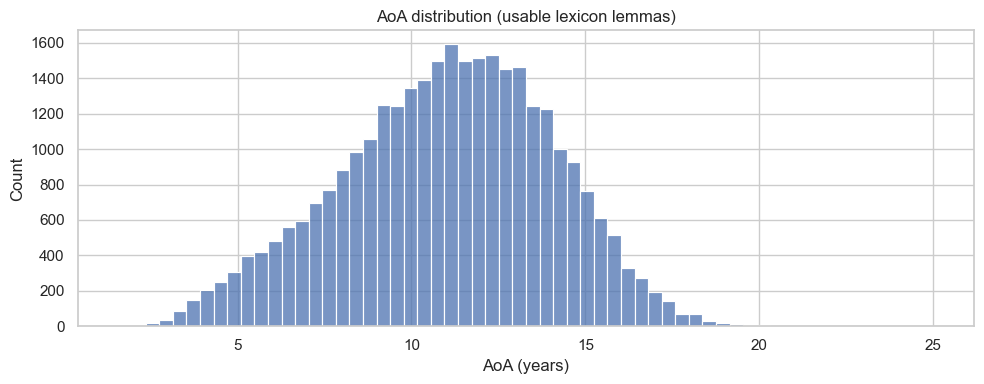

In [5]:
plt.figure(figsize=(10,4))
sns.histplot(aoa['aoa'], bins=60)
plt.title('AoA distribution (usable lexicon lemmas)')
plt.xlabel('AoA (years)')
plt.tight_layout()

# plt.figure(figsize=(10,4))
# sns.kdeplot(aoa['aoa'], bw_adjust=1.1)
# plt.title('AoA density (usable lexicon lemmas)')
# plt.xlabel('AoA (years)')
# plt.tight_layout()

aoa['aoa'].describe()


### Pretrained embedding + clustering (lexicon concepts)

This defines semantic "concepts" as clusters of AoA lemmas in a fixed pretrained word-vector space.


In [6]:
EMBEDDING_NAME = 'glove-wiki-gigaword-100'

import gensim.downloader as api
wv = api.load(EMBEDDING_NAME)
print('loaded embedding:', EMBEDDING_NAME, 'dim=', wv.vector_size)

aoa2 = aoa[aoa['lemma'].apply(lambda w: w in wv)].copy()
print('AoA lemmas in embedding vocab:', len(aoa2), '/', len(aoa))


loaded embedding: glove-wiki-gigaword-100 dim= 100
AoA lemmas in embedding vocab: 29163 / 31104


In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

X = np.vstack([wv[w] for w in aoa2['lemma'].tolist()]).astype(np.float32)
y_aoa = aoa2['aoa'].to_numpy(dtype=np.float32)

sc = StandardScaler(with_mean=True, with_std=True)
Xz = sc.fit_transform(X)

K = 25
km = KMeans(n_clusters=K, random_state=0, n_init='auto')
lab = km.fit_predict(Xz)

word_clusters = pd.DataFrame({'lemma': aoa2['lemma'].tolist(), 'aoa': y_aoa, 'cluster': lab})

summ = (
    word_clusters.groupby('cluster')
      .agg(n_words=('lemma','size'), mean_aoa=('aoa','mean'), std_aoa=('aoa','std'))
      .reset_index()
      .sort_values('mean_aoa')
)

def top_words_for_cluster(c, n=14):
    g = word_clusters[word_clusters['cluster']==c].sort_values('aoa')
    a = g['lemma'].head(n//2).tolist()
    b = g['lemma'].tail(n - n//2).tolist()
    return ', '.join(a + b)

summ['example_words'] = summ['cluster'].apply(top_words_for_cluster)
summ.head(10)


,cluster,n_words,mean_aoa,std_aoa,example_words
1,1,1033,6.514081,2.047210,"mom, yes, dad, count, mother, my, no, virtuall..."
4,4,714,8.650331,3.411793,"spoon, carrot, snack, eat, cake, chicken, oran..."
9,9,576,8.932064,2.622131,"jump, ball, leg, lap, cup, butt, plate, isthmi..."
19,19,967,9.323294,3.068445,"shoe, nose, toe, neck, clothes, hair, yellow, ..."
11,11,674,9.586924,2.846597,"water, wet, sun, hill, mouth, rain, cloud, geo..."
0,0,597,9.587261,2.680040,"fly, fire, arm, car, kitty, nighttime, truck, ..."
3,3,593,9.794170,2.961442,"birthday, house, head, chair, friend, brother,..."
16,16,727,9.856660,2.843594,"toy, cartoon, soap, rock, sing, tv, movie, lex..."
14,14,831,9.931391,2.980344,"bed, bathroom, door, bathtub, bath, backyard, ..."
13,13,1042,10.051270,3.188817,"dog, animal, flower, puppy, spider, duck, bird..."


### Optimal AoA cutoffs (2-bin and 3-bin) by separability search

This finds thresholds on **AoA** that maximize separability in the embedding space (no fixed quantiles).


In [9]:
def _centroid_sep(X, mask_a):
    A = X[mask_a]
    B = X[~mask_a]
    if len(A)==0 or len(B)==0:
        return -1.0
    return float(np.linalg.norm(A.mean(axis=0) - B.mean(axis=0)))

def best_2bin_cutoff(X, y, min_frac=0.15, n_grid=140):
    y = np.asarray(y)
    lo, hi = np.quantile(y, [min_frac, 1-min_frac])
    ts = np.linspace(lo, hi, n_grid)
    best = (-1.0, None)
    for t in ts:
        m = y <= t
        if m.mean() < min_frac or (1-m.mean()) < min_frac:
            continue
        s = _centroid_sep(X, m)
        if s > best[0]:
            best = (s, float(t))
    return best

def between_scatter_objective(X, y, t1, t2):
    g1 = X[y <= t1]
    g2 = X[(y > t1) & (y <= t2)]
    g3 = X[y > t2]
    groups = [g1,g2,g3]
    if any(len(g)==0 for g in groups):
        return -1.0
    mus = [g.mean(axis=0) for g in groups]
    ns = [len(g) for g in groups]
    mu = (ns[0]*mus[0] + ns[1]*mus[1] + ns[2]*mus[2]) / float(sum(ns))
    return float(sum(n * np.dot(m-mu, m-mu) for n,m in zip(ns,mus)))

def best_3bin_cutoffs(X, y, min_frac=0.15, grid_n=55):
    y = np.asarray(y)
    qs = np.linspace(min_frac, 1-min_frac, grid_n)
    cands = np.quantile(y, qs)
    best = (-1.0, None, None)
    for i in range(len(cands)):
        for j in range(i+1, len(cands)):
            t1 = float(cands[i]); t2 = float(cands[j])
            f1 = np.mean(y <= t1)
            f2 = np.mean((y > t1) & (y <= t2))
            f3 = np.mean(y > t2)
            if min(f1,f2,f3) < min_frac:
                continue
            s = between_scatter_objective(X, y, t1, t2)
            if s > best[0]:
                best = (s, t1, t2)
    return best

S2, t = best_2bin_cutoff(Xz, y_aoa)
S3, t1, t2 = best_3bin_cutoffs(Xz, y_aoa)
print('Best 2-bin AoA cutoff:', t, 'stat=', S2)
print('Best 3-bin AoA cutoffs:', (t1, t2), 'stat=', S3)


Best 2-bin AoA cutoff: 7.579999923706055 stat= 3.016047477722168
Best 3-bin AoA cutoffs: (7.579999923706055, 11.59000015258789) stat= 47565.453125


## Part B — Map those concepts onto stories (Amazon age)

We embed each **event** in the same pretrained word-vector space and assign it to the nearest lexicon concept cluster. This gives you:

- `p(age_mid | concept)` via story-level concept counts.
- `p(concept | age_mid)` via smoothing over continuous `age_mid`.


In [10]:
def read_master() -> tuple[Path, pd.DataFrame]:
    candidates = [
        Path('data/processed/master_batch1.csv.gz'),
        Path('data/processed/master_batch1.parquet'),
        Path('data/processed/master_stories.csv.gz'),
        Path('data/processed/master_stories.parquet'),
    ]
    p = next((x for x in candidates if x.exists()), None)
    if p is None:
        raise FileNotFoundError('No master found under data/processed/')
    if p.suffix == '.parquet':
        df = pd.read_parquet(p)
    else:
        df = pd.read_csv(p, low_memory=False)
    return p, df


path, master = read_master()
master['age_mid'] = pd.to_numeric(master.get('age_mid'), errors='coerce')
stories = master[(master.get('review_events_json').notna()) & (master['age_mid'].notna())].copy()
print('Loaded:', path, master.shape)
print('Stories with events + age_mid:', len(stories))


Loaded: data/processed/master_batch1.csv.gz (2860, 551)
Stories with events + age_mid: 333


### Confound distributions (story-level)

Loads `artifacts/text_features_batch1_review_samples.csv` (if present) and shows:
- overall distributions of confounds + Amazon metadata
- continuous relationships vs `age_mid` (scatter + smooth)

These are the variables we later probe/control for.


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

feat_candidates = [
    Path("artifacts/text_features_batch1_review_samples.csv"),
    Path("artifacts/text_features_batch1.csv"),
    Path("artifacts/text_features.csv"),
]
feat_path = next((p for p in feat_candidates if p.exists()), None)
if feat_path is None:
    raise FileNotFoundError("No artifacts/text_features*.csv found. Run scripts/analyze_text_features.py first.")
feat = pd.read_csv(feat_path, low_memory=False)
feat["age_mid"] = pd.to_numeric(feat.get("age_mid"), errors="coerce")
feat = feat[feat["age_mid"].notna()].copy()
print("Loaded features:", feat_path, feat.shape)

# numeric Amazon metadata
for c in ["Num Reviews","Average Rating","Price","yt_view_count","yt_like_count","yt_duration"]:
    if c in feat.columns:
        feat[c] = pd.to_numeric(feat[c], errors="coerce")

confounds = [
    "num_words","num_sentences","mean_sentence_length_words","mean_word_length_chars",
    "ttr","mean_log10_corpus_freq","rare_frac_corpus_le_5",
    "flesch_kincaid_grade_est","avg_syllables_per_word",
    "aoa_mean","aoa_coverage",
    "sentiment_compound","sentiment_compound_mean","sentiment_compound_std",
    "concept_n_events_parsed","concept_mean_event_words",
]
confounds = [c for c in confounds if c in feat.columns]

# include category TF-IDF dims if present
cat_cols = [c for c in feat.columns if c.startswith("cat_tfidf_svd_")]
confounds2 = confounds + cat_cols[:8]  # show first few components

# Distributions
n = len(confounds)
cols = 3
rows = int(np.ceil(n/cols))
fig, axes = plt.subplots(rows, cols, figsize=(15, 4*rows))
axes = np.array(axes).reshape(-1)
for ax, c in zip(axes, confounds):
    x = pd.to_numeric(feat[c], errors="coerce")
    sns.kdeplot(x=x.dropna(), ax=ax)
    ax.set_title(c)
for ax in axes[len(confounds):]:
    ax.axis("off")
plt.suptitle("Confound distributions (overall)", y=1.01)
plt.tight_layout()

# Continuous relationships vs age_mid
n = min(len(confounds2), 12)
fig, axes = plt.subplots(4, 3, figsize=(15, 18))
axes = axes.flatten()
for ax, c in zip(axes, confounds2[:n]):
    d = feat[["age_mid", c]].copy()
    d[c] = pd.to_numeric(d[c], errors="coerce")
    d = d.dropna()
    sns.scatterplot(data=d, x="age_mid", y=c, ax=ax, s=12, alpha=0.25)
    sns.regplot(data=d, x="age_mid", y=c, ax=ax, scatter=False, lowess=True, line_kws={"color":"black"})
    ax.set_title(c)
for ax in axes[n:]:
    ax.axis("off")
plt.suptitle("Confounds vs Amazon age_mid (LOWESS)", y=1.01)
plt.tight_layout()

# Category parent distribution (if available)
if "Categories" in feat.columns:
    def parent_cat(s):
        parts = [p.strip() for p in str(s).split(">") if p and str(p).strip() and str(p).strip().lower() != "nan"]
        if not parts: return ""
        return parts[-2] if len(parts)>=2 else parts[-1]
    feat["category_parent"] = feat["Categories"].apply(parent_cat)
    vc = feat["category_parent"].value_counts().head(20)
    plt.figure(figsize=(10,6))
    sns.barplot(x=vc.values, y=vc.index)
    plt.title("Top category_parent (count)")
    plt.tight_layout()
    display(vc)


In [11]:
def _safe_json_loads(x):
    if x is None:
        return None
    if isinstance(x, float) and np.isnan(x):
        return None
    if isinstance(x, (dict, list)):
        return x
    s = str(x).strip()
    if not s or s.lower() == 'nan':
        return None
    try:
        return json.loads(s)
    except Exception:
        return None

def iter_event_texts(review_events_json):
    events = _safe_json_loads(review_events_json)
    if not isinstance(events, list):
        return
    for e in events:
        if not isinstance(e, dict):
            continue
        sents = e.get('sentences')
        if not isinstance(sents, list):
            continue
        parts=[]
        for s in sents:
            if isinstance(s, dict) and 'text' in s:
                parts.append(str(s['text']))
            elif isinstance(s, str):
                parts.append(s)
        txt = ' '.join(p.strip() for p in parts if p and str(p).strip()).strip()
        if txt:
            yield txt

WORD_RE = re.compile(r"[A-Za-z']+")
try:
    import spacy
    _nlp = spacy.load('en_core_web_sm', disable=['parser','ner'])
    def lemmatize(text: str) -> list[str]:
        doc = _nlp(text)
        out=[]
        for t in doc:
            if not t.is_alpha or t.is_stop:
                continue
            lem = (t.lemma_ or '').lower().strip()
            if lem and lem != '-pron-':
                out.append(lem)
        return out
    print('Using spaCy lemmatizer')
except Exception as e:
    def _lemma_heuristic(w: str) -> str:
        w = w.lower().strip("'")
        for suf in ['ing','ed','ies','s']:
            if len(w) > 4 and w.endswith(suf):
                if suf == 'ies':
                    return w[:-3] + 'y'
                if suf == 's':
                    return w[:-1]
                return w[:-len(suf)]
        return w
    def lemmatize(text: str) -> list[str]:
        toks = [t.lower() for t in WORD_RE.findall(text)]
        toks = [t for t in toks if len(t) >= 2]
        return [_lemma_heuristic(t) for t in toks]
    print('Using heuristic lemmatizer:', repr(e)[:160])


Using heuristic lemmatizer: ModuleNotFoundError("No module named 'spacy'")


### Story-level AoA vs Amazon age (pre-concept)

This computes AoA statistics directly from each story's event lemmas and relates them to `age_mid` **before** any concept clustering.


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
try:
    from scipy.stats import spearmanr
except Exception:
    spearmanr = None

import seaborn as sns
import matplotlib.pyplot as plt

aoa_map = dict(zip(aoa["lemma"].tolist(), aoa["aoa"].tolist()))
rows=[]
for row in stories.itertuples(index=False):
    sid = getattr(row, "story_id", None)
    age_mid = float(getattr(row, "age_mid"))
    total_tokens = 0
    matched = []
    for ev_txt in iter_event_texts(getattr(row, "review_events_json")):
        toks = lemmatize(ev_txt)
        total_tokens += len(toks)
        for t in toks:
            v = aoa_map.get(t)
            if v is not None and not (isinstance(v, float) and np.isnan(v)):
                matched.append(float(v))
    if not matched:
        continue
    arr = np.array(matched, dtype=float)
    rows.append({
        "story_id": sid,
        "age_mid": age_mid,
        "aoa_mean_story": float(arr.mean()),
        "aoa_median_story": float(np.median(arr)),
        "aoa_std_story": float(arr.std(ddof=0)),
        "aoa_p90_story": float(np.quantile(arr, 0.90)),
        "aoa_max_story": float(arr.max()),
        "aoa_n_matched": int(len(arr)),
        "aoa_total_tokens": int(total_tokens),
        "aoa_coverage_story": float(len(arr) / max(1, total_tokens)),
    })

dsl = pd.DataFrame(rows)
print("stories with AoA coverage:", len(dsl))
display(dsl[["aoa_mean_story","aoa_std_story","aoa_p90_story","aoa_coverage_story"]].describe())

pairs = [("aoa_mean_story","Mean AoA"),("aoa_median_story","Median AoA"),("aoa_p90_story","AoA p90"),("aoa_std_story","AoA std")]
fig, axes = plt.subplots(2,2, figsize=(11,8))
axes = axes.flatten()
for ax,(col,title) in zip(axes,pairs):
    d = dsl[[col,"age_mid"]].dropna()
    X = d[[col]].to_numpy(); y = d["age_mid"].to_numpy()
    lr = LinearRegression().fit(X,y)
    pred = lr.predict(X)
    r2 = float(r2_score(y,pred))
    rho = float(spearmanr(d[col], d["age_mid"]).correlation) if spearmanr is not None else float("nan")
    sns.regplot(data=d, x=col, y="age_mid", ax=ax, scatter_kws={"s":12,"alpha":0.35}, line_kws={"color":"black"})
    ax.set_title(f"{title}: R²={r2:.3f}  ρ={rho:.3f}")
    ax.set_xlabel(col); ax.set_ylabel("age_mid")
plt.suptitle("Story-level: Amazon age vs AoA statistics", y=1.02)
plt.tight_layout()

# Max AoA is often length-sensitive; keep as diagnostic
plt.figure(figsize=(5.5,4.5))
d = dsl[["aoa_max_story","age_mid"]].dropna()
sns.regplot(data=d, x="aoa_max_story", y="age_mid", scatter_kws={"s":12,"alpha":0.35}, line_kws={"color":"black"})
plt.title("Story-level: Amazon age vs AoA max (diagnostic)")
plt.tight_layout()


In [ ]:
# Build token-level concept counts per story (using the lexicon word clusters)
# This avoids hard event->one-cluster assignment, and yields real concept mixtures.

lemma_to_cluster = dict(zip(word_clusters["lemma"].tolist(), word_clusters["cluster"].astype(int).tolist()))

rows=[]
for row in stories.itertuples(index=False):
    sid = getattr(row, 'story_id', None)
    age = float(getattr(row, 'age_mid'))
    # accumulate raw counts (or weights) per cluster over all event tokens
    ccounts = Counter()
    for ev_txt in iter_event_texts(getattr(row, 'review_events_json')):
        toks = lemmatize(ev_txt)
        for t in toks:
            c = lemma_to_cluster.get(t)
            if c is not None:
                ccounts[int(c)] += 1
    if not ccounts:
        continue
    for c, n in ccounts.items():
        rows.append({'story_id': sid, 'age_mid': age, 'cluster': int(c), 'n_tokens': int(n)})

story_concept = pd.DataFrame(rows)
print('stories with any concept tokens:', story_concept['story_id'].nunique())
print('clusters used:', story_concept['cluster'].nunique())
story_concept.head()


In [ ]:
# Normalize to per-story distributions for p(concept | age_mid)
wide = story_concept.pivot_table(index='story_id', columns='cluster', values='n_tokens', fill_value=0)
ages = story_concept.groupby('story_id')['age_mid'].first().loc[wide.index].to_numpy(dtype=float)

Xc = wide.to_numpy(dtype=np.float32)
row_sum = Xc.sum(axis=1, keepdims=True)
Xc = Xc / (row_sum + 1e-12)
clusters = wide.columns.to_numpy()

print('stories:', Xc.shape[0], 'clusters:', Xc.shape[1])
print('top1 mass (median/p90):', float(np.median(np.max(Xc, axis=1))), float(np.quantile(np.max(Xc, axis=1), 0.90)))


### p(age_mid | concept)

Summarize, for each concept cluster, the distribution of story ages where that concept appears.


In [ ]:
# p(age_mid | concept)
# Summarize, for each concept cluster, the distribution of story ages where that concept appears.

print('concept rows:', len(story_concept))


def concept_age_summary(df: pd.DataFrame) -> pd.DataFrame:
    rows=[]
    for c, g in df.groupby('cluster'):
        ages = g['age_mid'].to_numpy(dtype=float)
        rows.append({
            'cluster': int(c),
            'n_stories': int(g['story_id'].nunique()),
            'n_tokens_total': int(g['n_tokens'].sum()) if 'n_tokens' in g.columns else int(len(g)),
            'age_mean': float(np.mean(ages)),
            'age_median': float(np.median(ages)),
        })
    return pd.DataFrame(rows).sort_values('age_median')

age_summ = concept_age_summary(story_concept)
age_summ = age_summ.merge(summ[['cluster','mean_aoa','example_words']], on='cluster', how='left')
age_summ.head(12)


#### Regressions: mean AoA ↔ mean/median Amazon age

- **Cluster-level:** relate each concept's `mean_aoa` to the Amazon `age_median` where it appears.
- **Story-level (optional):** compute mean AoA from story lemmas and regress against `age_mid`.


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
try:
    from scipy.stats import spearmanr
except Exception:
    spearmanr = None

import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Story-level AoA stats from event lemmas (computed from AoA lexicon)
aoa_map = dict(zip(aoa["lemma"].tolist(), aoa["aoa"].tolist()))
rows=[]
for row in stories.itertuples(index=False):
    sid = getattr(row, "story_id", None)
    age_mid = float(getattr(row, "age_mid"))
    total_tokens = 0
    matched = []
    for ev_txt in iter_event_texts(getattr(row, "review_events_json")):
        toks = lemmatize(ev_txt)
        total_tokens += len(toks)
        for t in toks:
            v = aoa_map.get(t)
            if v is not None and not (isinstance(v, float) and np.isnan(v)):
                matched.append(float(v))
    if not matched:
        continue
    arr = np.array(matched, dtype=float)
    rows.append({
        "story_id": sid,
        "age_mid": age_mid,
        "aoa_mean_story": float(arr.mean()),
        "aoa_median_story": float(np.median(arr)),
        "aoa_std_story": float(arr.std(ddof=0)),
        "aoa_p90_story": float(np.quantile(arr, 0.90)),
        "aoa_max_story": float(arr.max()),
        "aoa_n_matched": int(len(arr)),
        "aoa_total_tokens": int(total_tokens),
        "aoa_coverage_story": float(len(arr) / max(1, total_tokens)),
    })

dsl = pd.DataFrame(rows)
print("story-level rows with AoA coverage:", len(dsl))
dsl[["aoa_mean_story","aoa_std_story","aoa_p90_story","aoa_coverage_story"]].describe()

# Simple regressions + plots: AoA stats vs Amazon age
pairs = [
    ("aoa_mean_story", "Mean AoA"),
    ("aoa_median_story", "Median AoA"),
    ("aoa_p90_story", "AoA p90"),
    ("aoa_std_story", "AoA std"),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes = axes.flatten()
for ax, (col, title) in zip(axes, pairs):
    d = dsl[[col, "age_mid"]].dropna()
    X = d[[col]].to_numpy()
    y = d["age_mid"].to_numpy()
    lr = LinearRegression().fit(X, y)
    pred = lr.predict(X)
    r2 = float(r2_score(y, pred))
    rho = float(spearmanr(d[col], d["age_mid"]).correlation) if spearmanr is not None else float("nan")
    sns.regplot(data=d, x=col, y="age_mid", ax=ax, scatter_kws={"s":12,"alpha":0.35}, line_kws={"color":"black"})
    ax.set_title(f"{title}: R²={r2:.3f}  ρ={rho:.3f}")
    ax.set_xlabel(col)
    ax.set_ylabel("age_mid")

plt.suptitle("Story-level: Amazon age vs AoA statistics", y=1.02)
plt.tight_layout()

# Optional: show max as a separate diagnostic (often length-sensitive)
plt.figure(figsize=(5.5,4.5))
d = dsl[["aoa_max_story","age_mid"]].dropna()
sns.regplot(data=d, x="aoa_max_story", y="age_mid", scatter_kws={"s":12,"alpha":0.35}, line_kws={"color":"black"})
plt.title("Story-level: Amazon age vs AoA max (noisy/length-sensitive)")
plt.tight_layout()

dsl.head()


### p(concept | age_mid)

Smooth concept prevalence over continuous age using a Gaussian kernel.


In [ ]:
wide = story_concept.pivot_table(index='story_id', columns='cluster', values='n_tokens', fill_value=0)
ages = story_concept.groupby('story_id')['age_mid'].first().loc[wide.index].to_numpy(dtype=float)

# per-story concept distribution
Xc = wide.to_numpy(dtype=np.float32)
row_sum = Xc.sum(axis=1, keepdims=True)
Xc = Xc / (row_sum + 1e-12)
clusters = wide.columns.to_numpy()

print('stories:', Xc.shape[0], 'clusters:', Xc.shape[1])
print('nonzero events per story (min/median):', float(np.min(row_sum)), float(np.median(row_sum)))

# dominance diagnostic: how much mass is in the top-1 cluster per story?
top1 = np.max(Xc, axis=1)
print('top1 mass (median/p90):', float(np.median(top1)), float(np.quantile(top1, 0.90)))

age_grid = np.linspace(float(np.nanmin(ages)), float(np.nanmax(ages)), 60)
bandwidth = 0.6

def smooth_dist(a):
    w = np.exp(-0.5 * ((ages - a) / bandwidth) ** 2)
    w = w / (w.sum() + 1e-12)
    p = (w[:, None] * Xc).sum(axis=0)
    p = p / (p.sum() + 1e-12)
    return p

P = np.vstack([smooth_dist(a) for a in age_grid])
print('row sums (should be 1):', float(np.min(P.sum(axis=1))), float(np.max(P.sum(axis=1))))

# choose concepts that actually vary with age (variance over grid)
var = P.var(axis=0)
top = np.argsort(var)[::-1][:20]

plt.figure(figsize=(12,6))
sns.heatmap(
    P[:, top].T,
    cmap='mako',
    cbar_kws={'label': 'p(concept | age_mid)'},
    yticklabels=[f'c{int(clusters[i])}' for i in top],
)
plt.xticks(
    ticks=np.linspace(0, len(age_grid)-1, 8),
    labels=[f'{age_grid[i]:.1f}' for i in np.linspace(0, len(age_grid)-1, 8).astype(int)],
    rotation=0,
)
plt.xlabel('age_mid')
plt.ylabel('concept cluster')
plt.title('Smoothed concept distribution over continuous age')
plt.tight_layout()

# line plot of the top few varying concepts
plt.figure(figsize=(10,4))
for j in top[:6]:
    plt.plot(age_grid, P[:, j], label=f'c{int(clusters[j])}')
plt.xlabel('age_mid')
plt.ylabel('p(concept | age_mid)')
plt.title('Top varying concepts (smoothed)')
plt.legend(bbox_to_anchor=(1.02,1), loc='upper left')
plt.tight_layout()


### Save artifacts


In [32]:
out_dir = Path('artifacts/concept_age_unified')
out_dir.mkdir(parents=True, exist_ok=True)

word_clusters.to_csv(out_dir / 'word_clusters.csv', index=False)
summ.to_csv(out_dir / 'word_cluster_summary.csv', index=False)
age_summ.to_csv(out_dir / 'concept_age_summary.csv', index=False)
pd.DataFrame(P, columns=[f'cluster_{int(c)}' for c in clusters]).assign(age=age_grid).to_csv(
    out_dir / 'p_concept_given_age.csv', index=False
)

print('Wrote:', out_dir)


Wrote: artifacts/concept_age_unified
